## Data Science Project - Flight Price Prediction  1/2


### Step 1 – Load and Explore the Dataset 

In [2]:
# Installer les librairies
!pip install pandas numpy matplotlib seaborn scikit-learn flask 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns  #pour créer facilement des graphiques statistiques esthétiques,
# Charger les CSV
business_df = pd.read_csv("../DataSet/business.csv")
clean_dataset_df = pd.read_csv("../DataSet/Clean_Dataset.csv")
economy_df = pd.read_csv("../DataSet/economy.csv")

# Fonction pour afficher infos de base
def explore_df(df, name):
    print(f"\n--- Aperçu de {name} ---")
    print(df.head())          # 5 premières lignes
    print("\nStructure :")
    print(df.info())          # info colonnes et types
    print("\nStatistiques numériques :")
    print(df.describe())      # statistiques

    print("\nTypes de colonnes :")
    cat_cols = df.select_dtypes(include=['object']).columns
    num_cols = df.select_dtypes(include=['int64','float64']).columns
    print("Catégorielles :", list(cat_cols))
    print("Numériques :", list(num_cols))

# Explorer chaque dataset
explore_df(business_df, "Business")
explore_df(clean_dataset_df, "Clean_Dataset")
explore_df(economy_df, "Economy")


--- Aperçu de Business ---
         date    airline ch_code  num_code dep_time   from time_taken  \
0  11-02-2022  Air India      AI       868    18:00  Delhi    02h 00m   
1  11-02-2022  Air India      AI       624    19:00  Delhi    02h 15m   
2  11-02-2022  Air India      AI       531    20:00  Delhi    24h 45m   
3  11-02-2022  Air India      AI       839    21:25  Delhi    26h 30m   
4  11-02-2022  Air India      AI       544    17:15  Delhi    06h 40m   

                                                stop arr_time      to   price  
0                                          non-stop     20:00  Mumbai  25,612  
1                                          non-stop     21:15  Mumbai  25,612  
2  1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...    20:45  Mumbai  42,220  
3  1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...    23:55  Mumbai  44,450  
4  1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...    23:55  Mumbai  46,690  

Structure :
<class 'pandas.core.frame.DataFrame'>
Ra

### Step 2 – Data Preprocessing

In [2]:
# Travailler sur une copie, pour éviter de modifier l'original
df = clean_dataset_df.copy()

# Gérer les valeurs manquantes
print("\nValeurs manquantes avant de gérer les valeurs manquantes:")
print(df.isnull().sum())

# Séparer colonnes numériques et catégorielles
num_cols = df.select_dtypes(include=['int64','float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

# Pour les colonnes numériques : remplir les nulls avec médiane :robuste aux valeurs extrêmes 
for col in num_cols:
    if df[col].isnull().any():  # si NaN existe
         df[col] = df[col].fillna(df[col].median())

# Pour les colonnes catégorielles : forward fill puis backward fill si besoin
for col in cat_cols:
     if df[col].isnull().any():
        df[col] = df[col].bfill()
        df[col] = df[col].ffill()

print("\nValeurs manquantes après gestion des valeurs manquantes : ")
print(df.isnull().sum())

# Supprimer les colonnes inutiles **avant One-Hot Encoding**
# Remarque importante :
# La colonnes 'flight'créera beaucoup trop de colonnes après One-Hot Encoding
# et la colonne 'Unnamed:0' n'a pas d'intéret pour la prédiction
# Donc : ON SUPPRIME 'Unnamed: 0' ,  'flight' doit rester dans le DataFrame mais ne pas etre encodé AVANT LE ENCODAGE pour réduire les dimensions

df = df.drop(columns=["Unnamed: 0"], errors='ignore')

# Recalcule des colonnes numériques et catégorielles après suppression 
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

# Retirer 'flight' de la liste des colonnes à encoder (mais pas du DataFrame )
cat_cols = [col for col in cat_cols if col != "flight"]

# Encoder les variables catégorielles : transformer une colonne catégorielle en plusieurs colonnes 0/1 (si on a k categories donc -> k colonnes)
# One-Hot Encoding (drop_first=True pour éviter multicolinéarité) (k categories -> k-1 colonnes et la categorie supprimé devient la catgorie de référence)

# on encode toutes les colonnes catégorielles SAUF "flight"
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# Feature Scaling : standardisation
# StandardScaler : (x - mean) / std
# Formule : x_scaled = (x - μ) / σ
for col in num_cols:
    mean = df[col].mean()
    std = df[col].std()
    df[col] = (df[col] - mean) / std

print("\nDataset après preprocessing et scaling")
print(df.head())


Valeurs manquantes avant de gérer les valeurs manquantes:
Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

Valeurs manquantes après gestion des valeurs manquantes : 
Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

Dataset après preprocessing et scaling
    flight  duration  days_left     price  airline_Air_India  \
0  SG-8709 -1.397528  -1.843872 -0.658067              False   
1  SG-8157 -1.375282  -1.843872 -0.658067              False   
2   I5-764 -1.397528  -1.843872 -0.657935              False   
3   UK-995 -1.386405  -1.843872

### Step 3 – Exploratory Data Analysis (EDA)
On a
 df = dataset complet après encodage et scaling \
Donc on doit creer autre dataframe eda_df = dataset pour exploration non encodé

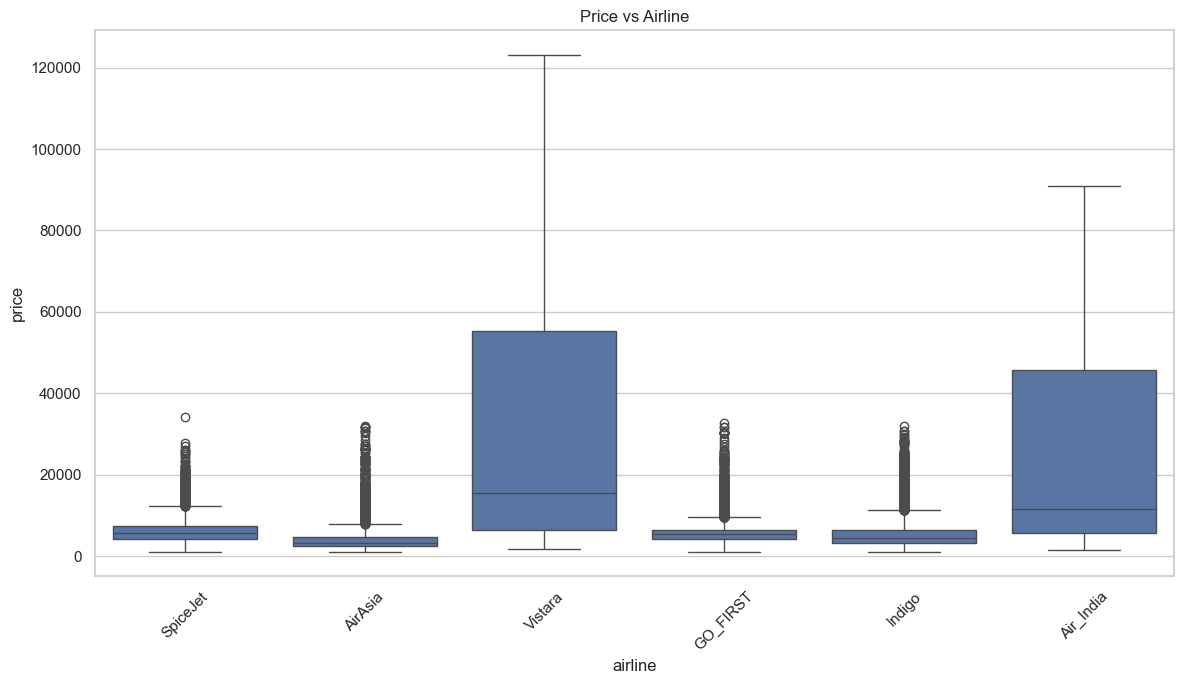

In [3]:
# Ajustements esthétiques pour plots
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 7)

# Créer un DataFrame pour l'EDA
eda_df = clean_dataset_df.copy()

#1 Price vs Airline : Boxplot
plt.figure()
sns.boxplot(x='airline', y='price', data=eda_df)
plt.title("Price vs Airline")   
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

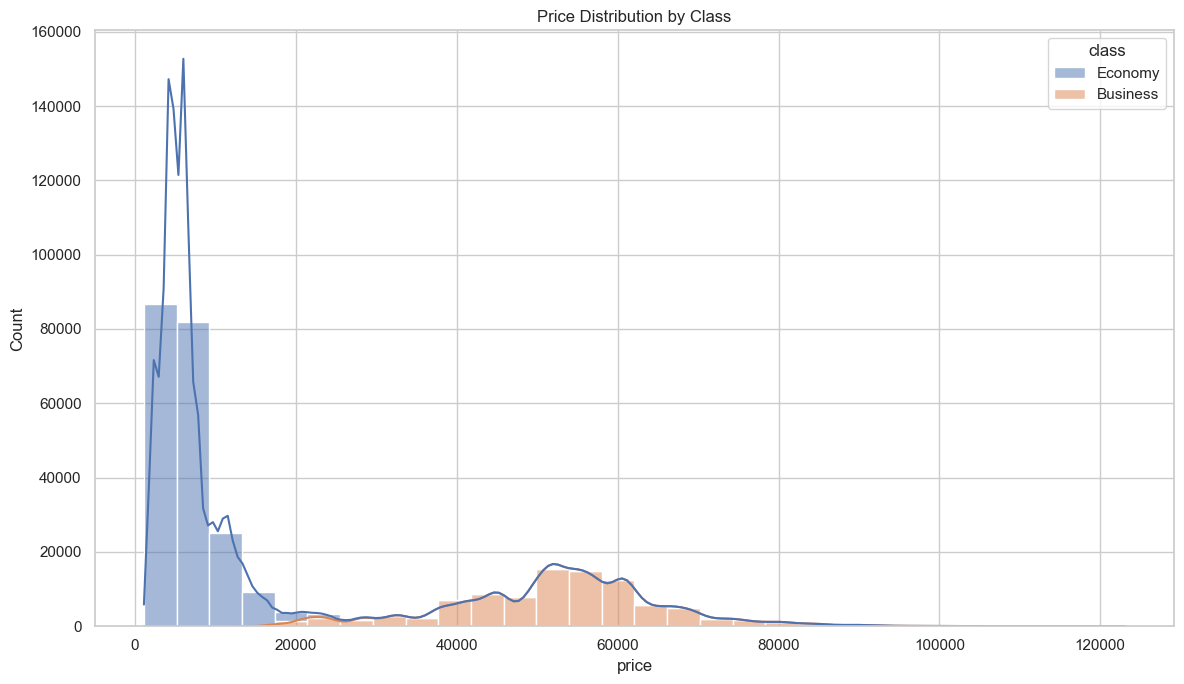

In [4]:
#2 Price vs Class : Histogram
plt.figure()
sns.histplot(data=eda_df, x='price', hue='class', bins=30, kde=True, multiple="stack")
plt.title("Price Distribution by Class")
plt.tight_layout()
plt.show()

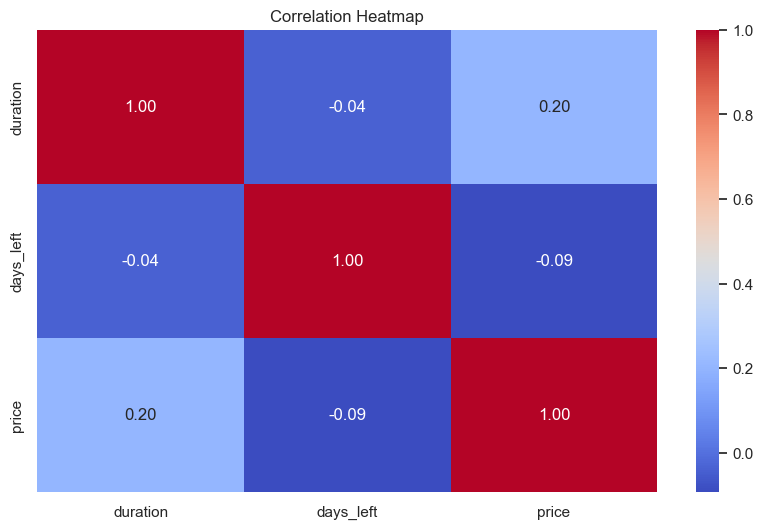

In [5]:
#3 Price vs Days Left : correlation heatmap
# Calculer la matrice de corrélation pour les colonnes numériques
numeric_df = eda_df[['duration', 'days_left', 'price']]

# Calculer la matrice de corrélation
corr_matrix = numeric_df.corr()

# Plot de la heatmap
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap")
plt.show()


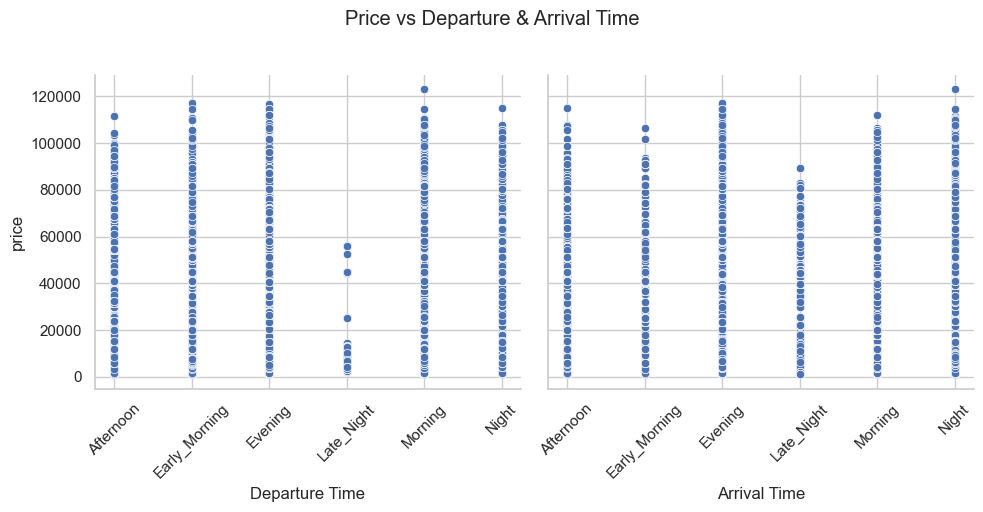

In [6]:
#4 Price vs Departure and Arrival Time : pairplot
# Sélectionner les colonnes d’intérêt
subset = eda_df[['price', 'departure_time', 'arrival_time']].copy()

# Convertir les colonnes catégorielles en codes numériques
subset['departure_time_code'] = subset['departure_time'].astype('category').cat.codes
subset['arrival_time_code'] = subset['arrival_time'].astype('category').cat.codes

# Créer des mappings pour afficher les labels
dep_mapping = dict(enumerate(subset['departure_time'].astype('category').cat.categories))
arr_mapping = dict(enumerate(subset['arrival_time'].astype('category').cat.categories))

# Créer le pairplot
g = sns.pairplot(subset, y_vars=['price'], x_vars=['departure_time_code','arrival_time_code'], kind='scatter', height=5)
plt.suptitle("Price vs Departure & Arrival Time", y=1.02)

# Remplacer les ticks par les labels originaux pour chaque subplot
for i, ax in enumerate(g.axes[0]):  # axes[0] contient les subplots de la première ligne
    if i == 0:  # subplot pour departure_time
        ax.set_xticks(list(dep_mapping.keys()))
        ax.set_xticklabels(list(dep_mapping.values()), rotation=45)
        ax.set_xlabel("Departure Time")
    else:  # subplot pour arrival_time
        ax.set_xticks(list(arr_mapping.keys()))
        ax.set_xticklabels(list(arr_mapping.values()), rotation=45)
        ax.set_xlabel("Arrival Time")

plt.tight_layout()
plt.show()




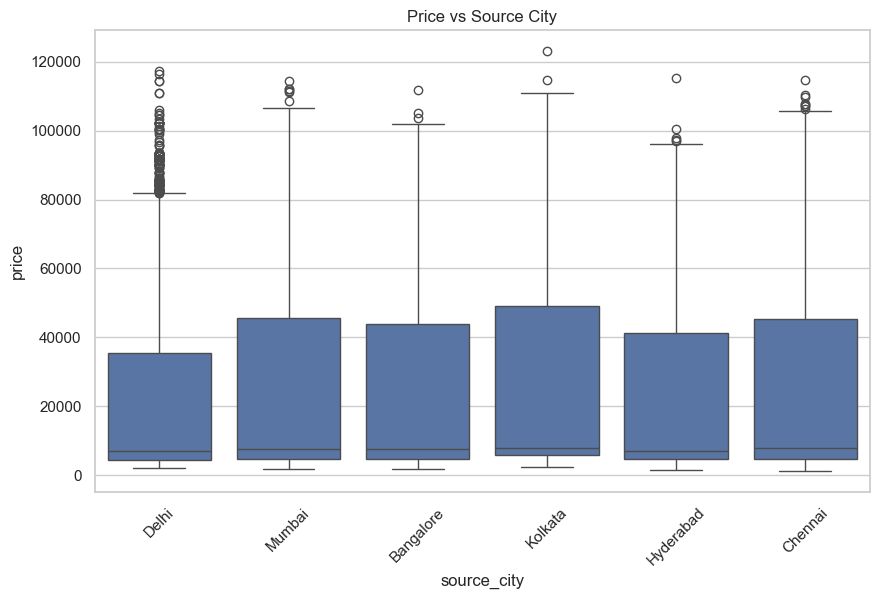

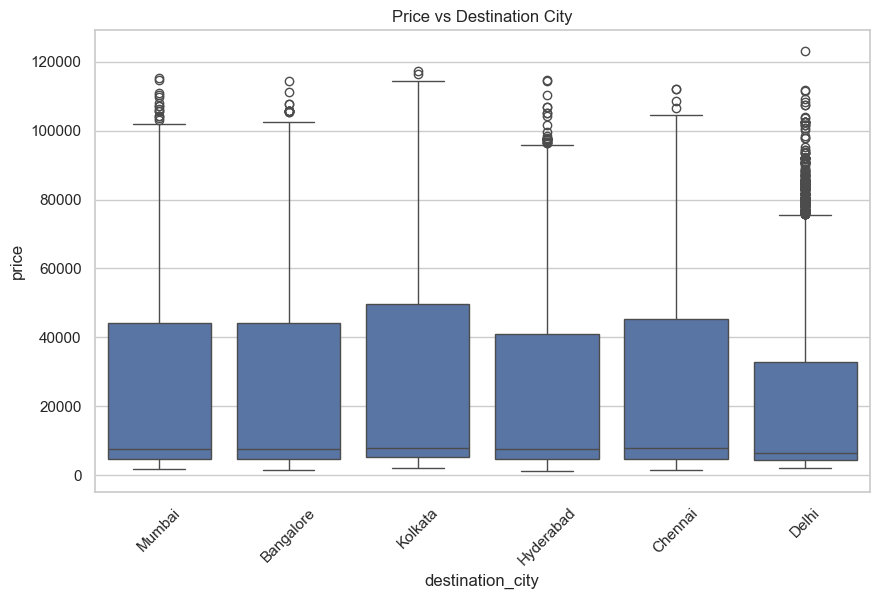

In [7]:
#5 Price vs Source and Destination : boxplot
# Histogramme du prix par Source City
plt.figure(figsize=(10,6))
sns.boxplot(x='source_city', y='price', data=eda_df)
plt.title("Price vs Source City")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10,6))
sns.boxplot(x='destination_city', y='price', data=eda_df)
plt.title("Price vs Destination City")
plt.xticks(rotation=45)
plt.show()


### Step 4 – Feature Selection
##### Analyse de correlation
On a visualisé la corrélation pour les variables numériques avec le prix , voir graphique #3 Price vs Days Left : correlation heatmap \
On utilise df car il contient déjà les variables catégorielles encodées et les colonnes numériques scalées après preprocessing.

##### Remarque importante:
La colonne 'Unnamed' est l'index du fichier csv , il faut donc la supprimer avant d’entraîner le modèle de feature importance & SelectKBest

Top 10 important features (Random Forest):
 class_Economy                 0.880059
duration                      0.058490
days_left                     0.018570
airline_Vistara               0.009551
source_city_Delhi             0.003820
destination_city_Delhi        0.003634
source_city_Mumbai            0.002401
destination_city_Mumbai       0.002103
source_city_Kolkata           0.001949
destination_city_Hyderabad    0.001912
dtype: float64


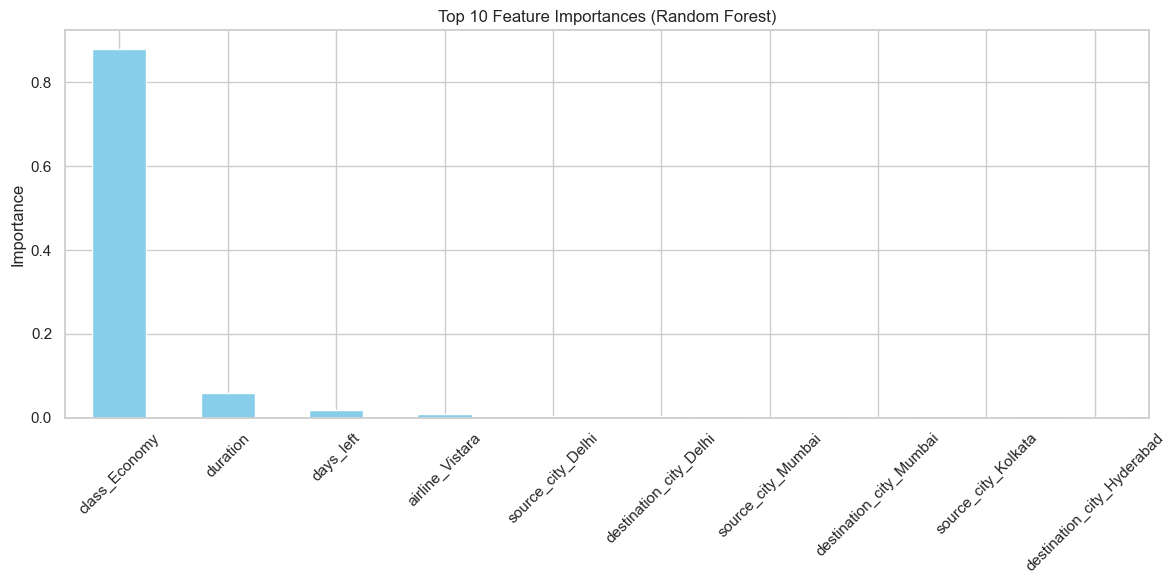

In [10]:
 #feature importance

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression

# RQ : on utilise df qui est déjà encodé et scalé
# df contient toutes les colonnes numériques et encodées y compris les variables catégorielles déjà converties en 0/1

# Séparer les features et la target
X = df.drop(['price', 'flight'], axis=1)  # toutes les colonnes num sauf 'price' et 'flight'
y = df['price']

# Créer et entraîner le modèle Random Forest
rf = RandomForestRegressor(random_state=2000, n_jobs=-1)
rf.fit(X, y)

# Récupérer les importances des features
importances = pd.Series(rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

# Afficher les 10 features les plus importantes
print("Top 10 important features (Random Forest):\n", importances.head(10))

# Visualiser les 10 features les plus importantes
plt.figure(figsize=(12,6))
importances.head(10).plot(kind='bar', color='skyblue')
plt.title("Top 10 Feature Importances (Random Forest)")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
# Sélection des features avec SelectKBest

# Sélectionner les 10 meilleures features selon f_regression
selector = SelectKBest(score_func=f_regression, k=10)
selector.fit(X, y)

# Récupérer les features sélectionnées
selected_features = X.columns[selector.get_support()]
print("Top 10 features sélectionnées par SelectKBest:\n", selected_features)

Top 10 features sélectionnées par SelectKBest:
 Index(['duration', 'days_left', 'airline_Air_India', 'airline_GO_FIRST',
       'airline_Indigo', 'airline_SpiceJet', 'airline_Vistara', 'stops_zero',
       'arrival_time_Late_Night', 'class_Economy'],
      dtype='object')


Avant de passer à l'étape 5, onva sauvegarder le df actuel encodé et standardisé dans un CSV pour pouvoir le réutiliser dans un nouveau notebook

In [13]:
df.to_csv("../DataSet/Clean_Dataset_scaled.csv", index=False)

In [14]:
df.head()

,flight,duration,days_left,price,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,source_city_Chennai,...,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai,class_Economy
0,SG-8709,-1.397528,-1.843872,-0.658067,False,False,False,True,False,False,...,False,False,False,True,False,False,False,False,True,True
1,SG-8157,-1.375282,-1.843872,-0.658067,False,False,False,True,False,False,...,False,False,True,False,False,False,False,False,True,True
2,I5-764,-1.397528,-1.843872,-0.657935,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,True
3,UK-995,-1.386405,-1.843872,-0.657979,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,True,True
4,UK-963,-1.375282,-1.843872,-0.657979,False,False,False,False,True,False,...,False,False,True,False,False,False,False,False,True,True
